# Leaching, the lever rule and Hunter-Nash, and a partially miscible extraction cascade

`Leacher` (countercurrent leaching and washing, constant or variable underflow), the ternary-diagram helpers
(`mix`, `lever_rule`, `tie_line_through`, `hunter_nash`, `plot_hunter_nash`) and the rigorous
`CascadeParams(model="rigorous")` built on the differentiable `ternary_lle_flash`.

**What is and is not checked.** No published textbook example is reproduced: the numbers cited in the
issue could not be retrieved, so none is claimed. The leaching systems here are made up (a beet-like
washing problem and a synthetic oilseed-like underflow table), and the ternary is a SYNTHETIC type-I
system with illustrative NRTL parameters, not acetic acid-water-MIBK. The checks are analytic
(washing closed form, Kremser limit, lever rule) and cross-method (Hunter-Nash against the rigorous solve).

In [1]:
import jax, jax.numpy as jnp, numpy as np
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt

from difflow import (make_stream, Leacher, LeacherParams, washing_recovery, washing_stages,
                     ternary_lle, lever_rule, tie_line_through, hunter_nash)
from difflow.phase_diagrams import mix
from difflow.units.lle import (CascadeParams, LLEEquilibrium, MultistageCascade, NRTLParams,
                               ternary_lle_flash)
from difflow.visualization import plot_hunter_nash

## 1. Washing and leaching with constant underflow

100 kg/s of pulp carries 200 kg/s of sugar solution (10 % sugar). Fresh water is the solvent; the
underflow holds 2 kg solution per kg pulp. Flows in this unit are kg/s.

In [2]:
feed = make_stream({"pulp": 100.0, "sugar": 20.0, "water": 180.0}, 300.0, 1e5)
water = make_stream({"water": 150.0}, 300.0, 1e5)

def leach(**kw):
    p = LeacherParams("pulp", "sugar", "water", **{"underflow": 2.0, **kw})
    return Leacher(p)

under, over, info = leach(n_stages=3.0)(feed, water)
w = 150.0 / 200.0
print(f"recovery {float(info['recovery']):.4f}  (washing closed form {float(washing_recovery(w, 3.0)):.4f})")
print(f"liquor {float(info['y_overflow']):.4f} mass fraction sugar, spent-solids solution {float(info['y_underflow']):.4f}")
print("per-stage solute mass fraction:", np.round(np.asarray(info["stage_y"]), 4))

recovery 0.6343  (washing closed form 0.6343)
liquor 0.0846 mass fraction sugar, spent-solids solution 0.0366
per-stage solute mass fraction: [0.0846 0.064  0.0366]


The feed holds as much solution as the underflow does, so this is a pure wash and the stage relation is the
Kremser form in the wash ratio `w = V/L`. The stage count is a real number, so it is a design variable:

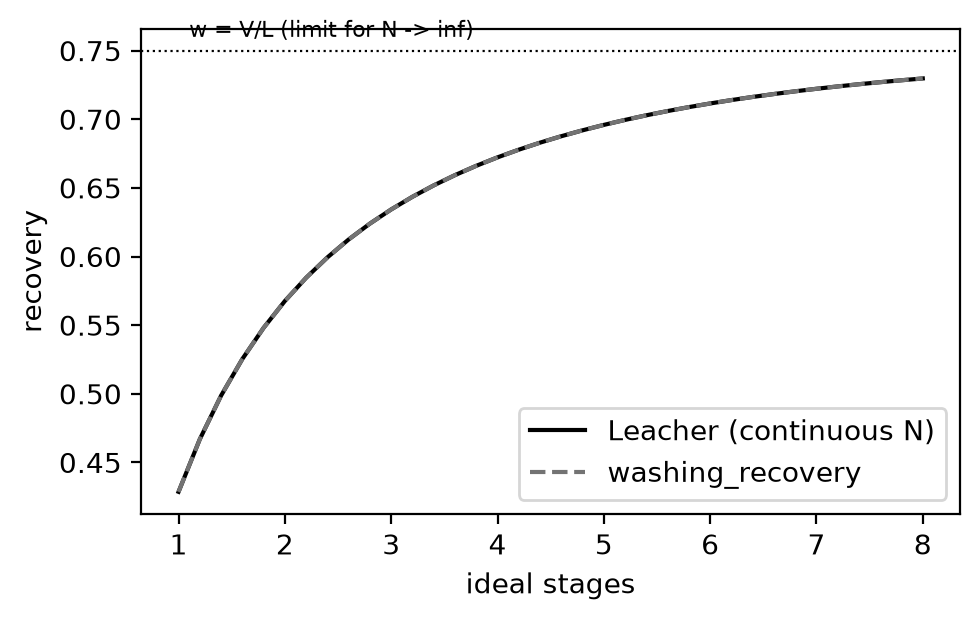

In [3]:
N = jnp.linspace(1.0, 8.0, 36)
rec = jnp.array([float(leach(n_stages=float(n))(feed, water)[2]["recovery"]) for n in N])
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(N, rec, "-", color="k", label="Leacher (continuous N)")
ax.plot(N, washing_recovery(w, N), "--", color="0.45", label="washing_recovery")
ax.axhline(w, ls=":", color="k", lw=0.8); ax.text(1.1, w + 0.01, "w = V/L (limit for N -> inf)", fontsize=8)
ax.set_xlabel("ideal stages"); ax.set_ylabel("recovery"); ax.legend(); plt.tight_layout(); plt.show()

When the feed solids carry a different amount of solution than the underflow does, the first stage is special
(`V_1 = V + L_0 - L`); the closed form handles it. Design modes: the stages for a recovery, or the water rate
for a given number of stages (here with `w > 1`, so any recovery is reachable).

In [4]:
big = make_stream({"water": 240.0}, 300.0, 1e5)
_, _, i1 = Leacher(LeacherParams("pulp", "sugar", "water", underflow=2.0, recovery=0.95, design="stages"))(feed, big)
print(f"stages for 95 %: {float(i1['n_stages']):.3f}   (washing_stages: {float(washing_stages(1.2, 0.95)):.3f})")
_, _, i2 = Leacher(LeacherParams("pulp", "sugar", "water", n_stages=3.0, underflow=2.0,
                                 recovery=0.95, design="solvent"))(feed, water)
print(f"water for 95 % in 3 stages: {float(i2['solvent_rate']):.1f} kg/s")
# unreachable: w = 0.75 can never exceed 75 % recovery, flagged rather than silently wrong
_, _, i3 = Leacher(LeacherParams("pulp", "sugar", "water", underflow=2.0, recovery=0.9, design="stages"))(feed, water)
print("90 % at w = 0.75:", float(i3["n_stages"]), "feasible =", bool(i3["feasible"]))

stages for 95 %: 7.827   (washing_stages: 7.827)


water for 95 % in 3 stages: 452.9 kg/s
90 % at w = 0.75: nan feasible = False


## 2. Gradients: the solvent rate that minimises a recovery cost

Cost per second `c_w V + c_s (sugar left in the underflow)` at 3 stages. The recovery is differentiable in the
solvent rate, so a Newton iteration on the cost gradient finds the optimum.

In [5]:
c_w, c_s = 1.0, 60.0          # made-up unit costs

def cost(V):
    _, _, i = leach(n_stages=3.0)(feed, make_stream({"water": V}, 300.0, 1e5))
    return c_w * V + c_s * i["solute_in_underflow"]

g, h = jax.grad(cost), jax.grad(jax.grad(cost))
V = 150.0
for _ in range(8):
    V = V - g(V) / h(V)
print(f"optimum water rate {V:.1f} kg/s, cost {float(cost(V)):.2f}, gradient {float(g(V)):.1e}")
print(f"recovery there {float(leach(n_stages=3.0)(feed, make_stream({'water': V}, 300.0, 1e5))[2]['recovery']):.4f}")

optimum water rate 297.1 kg/s, cost 447.66, gradient -6.7e-16
recovery there 0.8746


## 3. Variable underflow (a synthetic oilseed-like table)

The solution an underflow carries grows with the solute concentration. The stage balances are then nonlinear
and are solved by a fixed number of Newton steps (integer stage count).

In [6]:
y_tab = [0.0, 0.1, 0.2, 0.4]
s_tab = [1.5, 1.8, 2.2, 3.0]
var = Leacher(LeacherParams("pulp", "sugar", "water", n_stages=3, underflow_model="variable",
                            underflow_y=y_tab, underflow_s=s_tab))
_, _, iv = var(feed, water)
print(f"variable underflow, 3 stages: recovery {float(iv['recovery']):.4f}, converged {bool(iv['converged'])}")
print("stage compositions:", np.round(np.asarray(iv["stage_y"]), 4))
print("underflow solution per kg pulp by stage:", np.round(np.asarray(iv["stage_L"]) / 100.0, 3))
print(f"constant underflow of 2.0 for comparison: {float(leach(n_stages=3.0)(feed, water)[2]['recovery']):.4f}")

variable underflow, 3 stages: recovery 0.7688, converged True
stage compositions: [0.08   0.0558 0.0293]
underflow solution per kg pulp by stage: [1.733 1.656 1.578]
constant underflow of 2.0 for comparison: 0.6343


## 4. The lever rule and Hunter-Nash on a ternary

A synthetic type-I system: `a` and `b` partially miscible, `s` the solute that prefers `b`.

In [7]:
tau = jnp.array([[0.0, 2.5, 0.5], [2.5, 0.0, 0.3], [0.8, 0.6, 0.0]])
nrtl = NRTLParams(("a", "b", "s"), tau, jnp.zeros((3, 3)), 0.3 * (1 - jnp.eye(3)))
data = ternary_lle(nrtl, 300.0, n_tie=30)

F = np.array([0.8, 0.0, 0.2]); S = np.array([0.0, 1.0, 0.0])
M = mix(jnp.stack([jnp.asarray(F), jnp.asarray(S)]), jnp.array([1.0, 1.0]))
tie = tie_line_through(data, M)
fI, fII = lever_rule(M, tie["x_I"], tie["x_II"])
print("mixing point", np.round(np.asarray(M), 3))
print(f"lever rule: phase I {float(fI):.4f}, phase II {float(fII):.4f}")
flash = ternary_lle_flash(nrtl, M, 300.0)
print(f"rigorous flash: beta = {float(flash['beta']):.4f}  (interpolated tie line {float(fII):.4f})")

mixing point [0.4 0.5 0.1]
lever rule: phase I 0.4252, phase II 0.5748


rigorous flash: beta = 0.5748  (interpolated tie line 0.5748)


Hunter-Nash: 3.18 stages (4 ideal), E1 = [0.067 0.783 0.149]


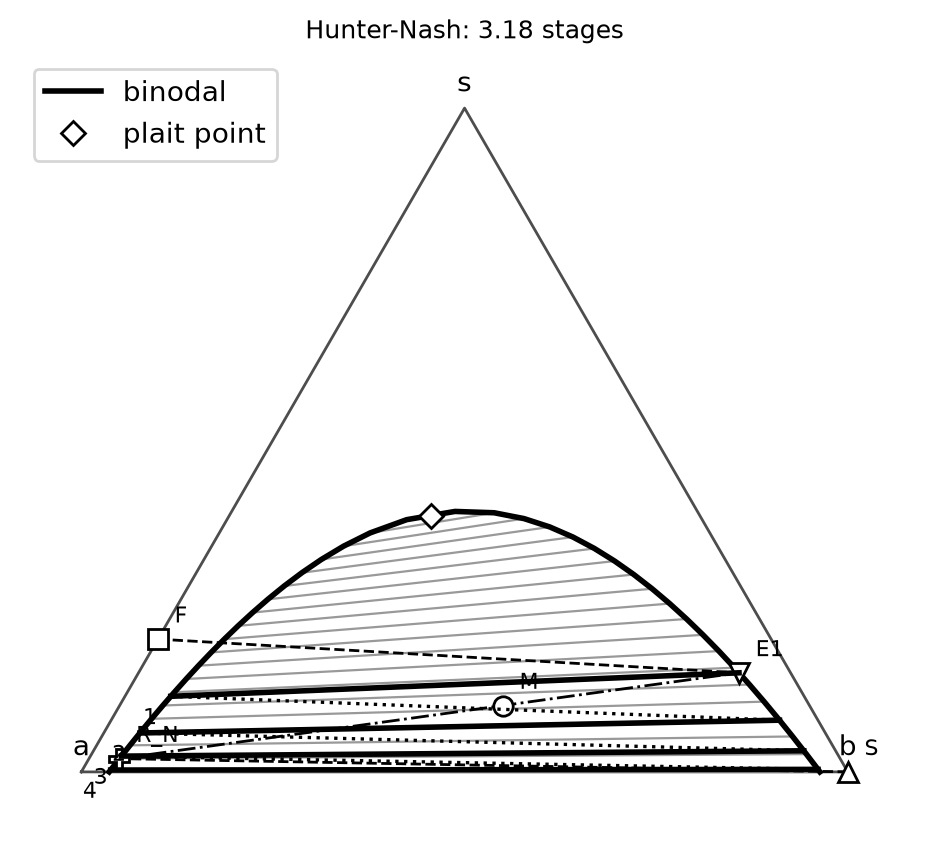

In [8]:
hn = hunter_nash(data, F, S, 0.02, S_over_F=1.0)
print(f"Hunter-Nash: {hn['n_stages']:.2f} stages ({hn['n_ideal']} ideal), E1 = {np.round(np.asarray(hn['E1']), 3)}")
ax = plot_hunter_nash(hn, coords="equilateral", labels=("a", "b", "s"))
ax.figure.set_size_inches(6, 5); plt.show()

## 5. The rigorous cascade (`model="rigorous"`)

Three countercurrent stages with the full two-liquid-phase equations: mutual solubility, variable phase flows,
all species in both phases. Same equilibrium model as the diagram above, so the Hunter-Nash stage count for the
rigorous raffinate should come back as 3.

In [9]:
nrtl_w = NRTLParams(("water", "mibk", "acid"), tau, jnp.zeros((3, 3)), 0.3 * (1 - jnp.eye(3)))   # same numbers, role names
eq = LLEEquilibrium(solutes=["acid"], aqueous_carrier="water", organic_carrier="mibk",
                    nrtl_params=nrtl_w, activity_model="NRTL")
fd = make_stream({"water": 80.0, "mibk": 0.0, "acid": 20.0}, 300.0, 1e5)
sv = make_stream({"water": 0.0, "mibk": 100.0, "acid": 0.0}, 300.0, 1e5)
raff, ext, info = MultistageCascade(CascadeParams(3, eq, model="rigorous"))(fd, sv)
print("converged:", bool(info["converged"]), " residual:", float(info["residual"]))
for sp in ("water", "mibk", "acid"):
    print(f"{sp:6s} in {float(fd['F_' + sp]) + float(sv['F_' + sp]):8.3f}  out {float(raff['F_' + sp]) + float(ext['F_' + sp]):8.3f}")
R = np.array([float(raff["F_water"]), float(raff["F_mibk"]), float(raff["F_acid"])])
print(f"acid left in the raffinate {R[2]:.3f}; mibk lost to the raffinate {R[1]:.3f}")
print(f"Hunter-Nash stage count for that raffinate: {hunter_nash(data, F, S, R / R.sum(), S_over_F=1.0)['n_stages']:.4f}")

converged: True  residual: 6.661338147750939e-16
water  in   80.000  out   80.000
mibk   in  100.000  out  100.000
acid   in   20.000  out   20.000
acid left in the raffinate 1.678; mibk lost to the raffinate 3.069
Hunter-Nash stage count for that raffinate: 3.0000


Gradients flow through the rigorous solve (implicit-function derivative at the converged state):

In [10]:
def acid_left(mibk):
    sv = make_stream({"water": 0.0, "mibk": mibk, "acid": 0.0}, 300.0, 1e5)
    return MultistageCascade(CascadeParams(3, eq, model="rigorous"))(fd, sv)[0]["F_acid"]
f = jax.jit(acid_left)
d = float(jax.grad(f)(100.0))
fd_ = (float(f(100.0 + 1e-4)) - float(f(100.0 - 1e-4))) / 2e-4
print(f"d(acid left)/d(solvent) = {d:.6f}   finite difference {fd_:.6f}")

d(acid left)/d(solvent) = -0.036998   finite difference -0.036998
